In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)

numerical = list(
    df.dtypes[
        (df.dtypes == 'int64') | (df.dtypes == 'float64')
    ].index
)

In [5]:
numerical.remove('converted')

In [6]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [7]:
for col in df.columns:
    print(col)
    print()
    print(df[col].unique().tolist()[:5])
    print()

lead_source

['organic_search', 'social_media', 'referral', 'paid_ads', nan]

industry

['technology', 'retail', 'manufacturing', 'education', 'healthcare']

employment_status

['employed', 'student', nan, 'unemployed', 'self_employed']

location

['europe', 'south_america', nan, 'north_america', 'africa']

annual_income

[88160.0, 72688.0, 44697.0, nan, 24062.0]

number_of_courses_viewed

[3, 4, 2, 1, 0]

interaction_count

[4, 7, 6, 5, 9]

lead_score

[0.64, 0.72, 0.58, 0.57, 0.62]

converted

[1, 0]



In [8]:
df[categorical] = df[categorical].fillna('NA')

In [9]:
df[numerical] = df[numerical].fillna('0')

In [10]:
for col in df.columns:
    print(col)
    print()
    print(df[col].unique().tolist()[:5])
    print()

lead_source

['organic_search', 'social_media', 'referral', 'paid_ads', 'NA']

industry

['technology', 'retail', 'manufacturing', 'education', 'healthcare']

employment_status

['employed', 'student', 'NA', 'unemployed', 'self_employed']

location

['europe', 'south_america', 'NA', 'north_america', 'africa']

annual_income

[88160.0, 72688.0, 44697.0, '0', 24062.0]

number_of_courses_viewed

[3, 4, 2, 1, 0]

interaction_count

[4, 7, 6, 5, 9]

lead_score

[0.64, 0.72, 0.58, 0.57, 0.62]

converted

[1, 0]



In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lead_source               5000 non-null   str   
 1   industry                  5000 non-null   str   
 2   employment_status         5000 non-null   str   
 3   location                  5000 non-null   str   
 4   annual_income             5000 non-null   object
 5   number_of_courses_viewed  5000 non-null   int64 
 6   interaction_count         5000 non-null   int64 
 7   lead_score                5000 non-null   object
 8   converted                 5000 non-null   int64 
dtypes: int64(3), object(2), str(4)
memory usage: 351.7+ KB


In [25]:
df.describe(include="all")

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,5000,5000,5000,5000,5000,5000.000000,5000.000000,5000.00,5000.000000
unique,6,7,5,6,4314,NaN,NaN,100.00,NaN
top,organic_search,technology,employed,north_america,0,NaN,NaN,0.46,NaN
freq,1251,1173,2633,1371,369,NaN,NaN,114.00,NaN
mean,NaN,NaN,NaN,NaN,NaN,2.089400,4.472600,NaN,0.576600
std,NaN,NaN,NaN,NaN,NaN,1.188987,2.435906,NaN,0.494147
min,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,1.000000,3.000000,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,2.000000,4.000000,NaN,1.000000
75%,NaN,NaN,NaN,NaN,NaN,3.000000,6.000000,NaN,1.000000


In [28]:
corr = df[numerical].corr()

In [30]:
corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


<Axes: >

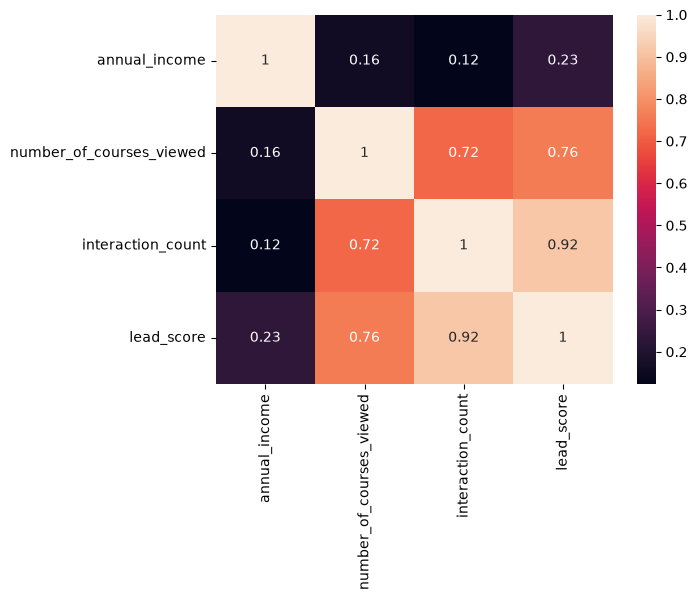

In [31]:
sns.heatmap(corr, annot=True)

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [13]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [14]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [15]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [16]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,finance,employed,asia,65980.0,2,3,0.37
1,events,finance,employed,south_america,71662.0,0,0,0.09
2,referral,NA,employed,asia,40220.0,2,5,0.55
3,organic_search,finance,employed,north_america,88352.0,2,2,0.45
4,events,technology,employed,north_america,89316.0,1,5,0
...,...,...,...,...,...,...,...,...
2995,paid_ads,finance,employed,asia,81522.0,1,3,0.29
2996,social_media,retail,employed,asia,33075.0,1,1,0.3
2997,organic_search,finance,employed,africa,71532.0,3,5,0.58
2998,social_media,retail,employed,asia,48836.0,0,0,0.03


In [40]:
from sklearn.metrics import mutual_info_score

In [41]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.converted)

In [42]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

lead_source          0.034761
employment_status    0.020313
industry             0.002898
location             0.001050
dtype: float64

In [17]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [18]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
# solver='lbfgs' is the default solver in newer version of sklearn
# for older versions, you need to specify it explicitly
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [49]:
y_pred = model.predict_proba(X_val)[:, 1]

In [50]:
y_pred

array([0.61726024, 0.44367734, 0.60433596, 0.64561808, 0.52216378,
       0.77882694, 0.6069766 , 0.54408125, 0.76768143, 0.52765589,
       0.75035232, 0.64699488, 0.56858224, 0.51045942, 0.59922295,
       0.46623742, 0.62786191, 0.69165742, 0.69081219, 0.59100747,
       0.49966606, 0.55591432, 0.65302709, 0.60793418, 0.72314073,
       0.51618038, 0.56141654, 0.57206181, 0.67042573, 0.55600211,
       0.63612056, 0.70335238, 0.45467969, 0.61896295, 0.65248445,
       0.42779984, 0.63941052, 0.62315054, 0.66028639, 0.51739237,
       0.53774738, 0.76070868, 0.48327899, 0.74090902, 0.63591779,
       0.41198764, 0.4537446 , 0.64172956, 0.4385467 , 0.8702356 ,
       0.724666  , 0.75641281, 0.5296771 , 0.66735431, 0.50446611,
       0.57644947, 0.72315272, 0.724947  , 0.65077024, 0.62896055,
       0.72114925, 0.59230929, 0.70823268, 0.61450345, 0.49693559,
       0.74442993, 0.52774374, 0.61402639, 0.55979285, 0.59025269,
       0.69366884, 0.72959152, 0.7610901 , 0.60743503, 0.52503

In [51]:
churn_decision = (y_pred >= 0.5)

In [52]:
(y_val == churn_decision).mean()

np.float64(0.645)

In [74]:
dv = DictVectorizer(sparse=False)

feature_imp = []

for feature in df_train.columns:
    df_train_copy = df_train.copy()
    df_val_copy = df_val.copy()
    
    del df_train_copy[feature]
    del df_val_copy[feature]

    train_dict = df_train_copy.to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    val_dict = df_val_copy.to_dict(orient='records')
    X_val = dv.transform(val_dict)
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)  
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    churn_decision = (y_pred >= 0.5)
    acc = (y_val == churn_decision).mean()

    feature_imp.append({'feature': feature, 'Accuracy': acc, 'Accuracy diff': np.abs((0.645-acc))})

df_feature_imp = pd.DataFrame(feature_imp)

In [75]:
df_feature_imp.sort_values(by='Accuracy diff', ascending=True)

,feature,Accuracy,Accuracy diff
1,industry,0.645,0.000
2,employment_status,0.645,0.000
3,location,0.645,0.000
7,lead_score,0.644,0.001
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.600,0.045
4,annual_income,0.727,0.082


In [20]:
from sklearn.linear_model import LogisticRegression

In [22]:
accuracy = []
for c in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    churn_decision = (y_pred >= 0.5)
    acc = (y_val == churn_decision).mean()

    accuracy.append({'C':c, 'Accuracy': acc})

df_accuracy = pd.DataFrame(accuracy)

In [23]:
df_accuracy

,C,Accuracy
0,0.000001,0.598
1,0.000010,0.598
2,0.000100,0.613
3,0.001000,0.645
